# SMOTE for Class Imbalance: Logistic Regression

Only about 6% of claims are fraud, so a model can look accurate while missing most fraud. This notebook tests whether **SMOTE** (Synthetic Minority Over-sampling Technique) helps the logistic regression baseline.

- **Part 1** is an exact copy of `Mohammad_Ikbal_Baseline_Models.ipynb` (same data cleaning, feature audit, 1994–1995 / 1996 split, encoding, scaling, model and evaluation). The only change is adding `imbalanced-learn` to the install cell.
- **Part 2** adds SMOTE to the training data, retrains logistic regression, and compares it with the baseline on the same untouched 1996 hold-out.

# Part 1: Baseline (copied from Mohammad_Ikbal_Baseline_Models)

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, confusion_matrix)

pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv('../data/fraud_oracle.csv')
print('Rows and columns:', df.shape)
display(df.head())
display(pd.DataFrame({'Data type': df.dtypes.astype(str),
                      'Missing values': df.isna().sum(),
                      'Unique values': df.nunique()}))
print('Duplicate rows:', df.duplicated().sum())
print('Rows with Age = 0:', (df['Age'] == 0).sum())

Rows and columns: (15420, 33)


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,Age,Fault,PolicyType,VehicleCategory,VehiclePrice,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,21,Policy Holder,Sport - Liability,Sport,more than 69000,0,1,12,300,1,more than 30,more than 30,none,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,34,Policy Holder,Sport - Collision,Sport,more than 69000,0,2,15,400,4,more than 30,more than 30,none,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,47,Policy Holder,Sport - Collision,Sport,more than 69000,0,3,7,400,3,more than 30,more than 30,1,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,65,Third Party,Sedan - Liability,Sport,20000 to 29000,0,4,4,400,2,more than 30,more than 30,1,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,27,Third Party,Sport - Collision,Sport,more than 69000,0,5,3,400,1,more than 30,more than 30,none,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


,Data type,Missing values,Unique values
Month,str,0,12
WeekOfMonth,int64,0,5
DayOfWeek,str,0,7
Make,str,0,19
AccidentArea,str,0,2
DayOfWeekClaimed,str,0,8
MonthClaimed,str,0,13
WeekOfMonthClaimed,int64,0,5
Sex,str,0,2
MaritalStatus,str,0,4


Duplicate rows: 0
Rows with Age = 0: 320


### I am keeping the remaining columns because we assume they are available when a claim is filed. We still need to confirm this with the data dictionary, especially for DriverRating, VehiclePrice, and PastNumberOfClaims. The columns below are excluded from this baseline as they are not all confirmed cases of leakage.

# Feature audit and final working decisions

In [4]:
# These columns should be out of the baseline for now.
# Some may contain information we would not know when a claim is first filed.
drop_reasons = {
    'Fault': 'Fault might be decided after an investigation.',
    'PolicyNumber': 'An ID number that also closely follows the year.',
    'RepNumber': 'An employee ID; we do not know when they were assigned.',
    'AgeOfPolicyHolder': 'The youngest age group appears only when Age is 0.',
    'PoliceReportFiled': 'The police report might be filed later.',
    'WitnessPresent': 'Witnesses might be found during the investigation.',
    'NumberOfSuppliments': 'More supplements could be added after filing.',
    'AddressChange_Claim': 'We need to confirm what this column means.',
    'Year': 'Used for the train/test split, not as a model input.'
}

# Showing what columns that are being dropped and the reasons for dropping them. 
drop_summary = pd.DataFrame(
    drop_reasons.items(),
    columns=['Column to drop', 'Reason']
)

display(drop_summary)

# Keep the remaining columns, excluding the label as well 
kept_columns = [
    column for column in df.columns
    if column not in drop_reasons and column != 'FraudFound_P'
]

print('Columns we are keeping:')
for column in kept_columns:
    print('-', column)

print('\nNumber of columns kept:', len(kept_columns))

,Column to drop,Reason
0,Fault,Fault might be decided after an investigation.
1,PolicyNumber,An ID number that also closely follows the year.
2,RepNumber,An employee ID; we do not know when they were ...
3,AgeOfPolicyHolder,The youngest age group appears only when Age i...
4,PoliceReportFiled,The police report might be filed later.
5,WitnessPresent,Witnesses might be found during the investigat...
6,NumberOfSuppliments,More supplements could be added after filing.
7,AddressChange_Claim,We need to confirm what this column means.
8,Year,"Used for the train/test split, not as a model ..."


Columns we are keeping:
- Month
- WeekOfMonth
- DayOfWeek
- Make
- AccidentArea
- DayOfWeekClaimed
- MonthClaimed
- WeekOfMonthClaimed
- Sex
- MaritalStatus
- Age
- PolicyType
- VehicleCategory
- VehiclePrice
- Deductible
- DriverRating
- Days_Policy_Accident
- Days_Policy_Claim
- PastNumberOfClaims
- AgeOfVehicle
- AgentType
- NumberOfCars
- BasePolicy

Number of columns kept: 23


# Create one training/hold-out split

In [5]:
train_df = df[df['Year'].isin([1994, 1995])].copy()
test_df = df[df['Year'] == 1996].copy()

assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(test_df.index)

split_summary = pd.DataFrame({
    'Split': ['Training: 1994–1995', 'Hold-out: 1996'],
    'Claims': [len(train_df), len(test_df)],
    'Fraud cases': [train_df['FraudFound_P'].sum(), test_df['FraudFound_P'].sum()],
    'Fraud rate': [train_df['FraudFound_P'].mean(), test_df['FraudFound_P'].mean()]
})
display(split_summary)

,Split,Claims,Fraud cases,Fraud rate
0,Training: 1994–1995,11337,710,0.062627
1,Hold-out: 1996,4083,213,0.052168


# Clean missing ages using the training median

In [6]:
for data in [train_df, test_df]:
    data['AgeMissing'] = ((data['Age'] == 0) | data['Age'].isna()).astype(int)
    data['Age'] = data['Age'].replace(0, np.nan)
    for column in ['MonthClaimed', 'DayOfWeekClaimed']:
        data[column] = data[column].replace('0', 'Unknown').fillna('Unknown')

training_median = train_df['Age'].median()
train_df['Age'] = train_df['Age'].fillna(training_median)
test_df['Age'] = test_df['Age'].fillna(training_median)
print('Training age median:', training_median)

input_columns = kept_columns + ['AgeMissing']
X_train = train_df[input_columns].copy()
y_train = train_df['FraudFound_P'].copy()
X_test = test_df[input_columns].copy()
y_test = test_df['FraudFound_P'].copy()
print('Input columns including AgeMissing:', len(input_columns))


Training age median: 38.0
Input columns including AgeMissing: 24


# One-hot encode categories 

In [7]:
category_columns = X_train.select_dtypes(include='object').columns.tolist()
category_columns += ['WeekOfMonth', 'WeekOfMonthClaimed', 'DriverRating']

X_train_encoded = pd.get_dummies(X_train, columns=category_columns, dtype=int)
X_test_encoded = pd.get_dummies(X_test, columns=category_columns, dtype=int)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
print('Training input shape:', X_train_encoded.shape)
print('Hold-out input shape:', X_test_encoded.shape)
assert not X_train_encoded.isna().any().any()
assert not X_test_encoded.isna().any().any()


Training input shape: (11337, 133)
Hold-out input shape: (4083, 133)


C:\Users\princ\AppData\Local\Temp\ipykernel_18672\820445371.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_columns = X_train.select_dtypes(include='object').columns.tolist()


# Scale age and deductible. Fit the scaler on training only. Leave 0/1 columns unchanged

In [8]:
numeric_columns = ['Age', 'Deductible']
scaler = StandardScaler()
X_train_ready = X_train_encoded.copy()
X_test_ready = X_test_encoded.copy()
X_train_ready[numeric_columns] = scaler.fit_transform(X_train_encoded[numeric_columns])
X_test_ready[numeric_columns] = scaler.transform(X_test_encoded[numeric_columns])


# Train Logistic Regression Baseline

In [9]:
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_ready, y_train)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

# Evaluate once on the hold-out
- Accuracy: fraction of all predictions that are correct.
- Precision: fraction of predicted fraud cases that actually are fraud.
- Recall: fraction of actual fraud cases caught.
- F1: combines precision and recall.
- Average precision (AP): a precision recall summary, labeled PR-AUC/AP. 

In [10]:
test_probabilities = model.predict_proba(X_test_ready)[:, 1]
test_predictions = (test_probabilities >= 0.5).astype(int)

never_fraud = np.zeros(len(y_test), dtype=int)
results = pd.DataFrame({
    'Approach': ['Always non-fraud reference', 'Logistic regression'],
    'Accuracy': [accuracy_score(y_test, never_fraud), accuracy_score(y_test, test_predictions)],
    'Precision': [0.0, precision_score(y_test, test_predictions, zero_division=0)],
    'Recall': [0.0, recall_score(y_test, test_predictions, zero_division=0)],
    'F1': [0.0, f1_score(y_test, test_predictions, zero_division=0)],
    'PR-AUC / AP': [average_precision_score(y_test, never_fraud),
                    average_precision_score(y_test, test_probabilities)]
})
display(results.round(4))
print('Percentage of claims flagged:', round(test_predictions.mean() * 100, 2))


,Approach,Accuracy,Precision,Recall,F1,PR-AUC / AP
0,Always non-fraud reference,0.9478,0.0000,0.000,0.0000,0.0522
1,Logistic regression,0.6111,0.0662,0.493,0.1168,0.0653


Percentage of claims flagged: 38.82


# Confusion Matrix

,Predicted non-fraud,Predicted fraud
Actual non fraud,2390,1480
Actual fraud,108,105


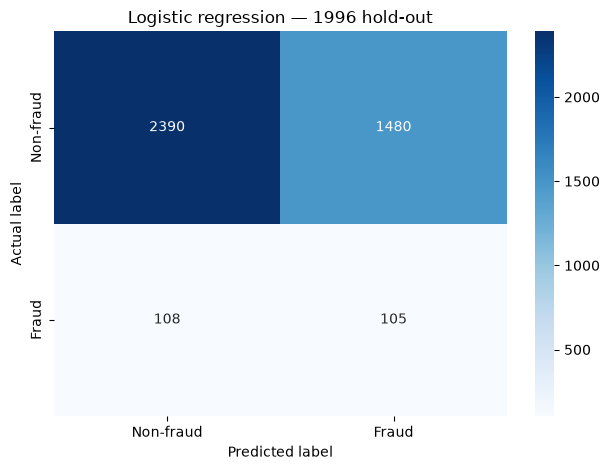

Correctly identified non-fraud: 2390
False alarms: 1480
Missed fraud: 108
Fraud cases caught: 105


In [11]:
matrix = confusion_matrix(y_test, test_predictions, labels=[0, 1])
display(pd.DataFrame(matrix, index=['Actual non fraud', 'Actual fraud'],
                     columns=['Predicted non-fraud', 'Predicted fraud']))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-fraud', 'Fraud'], yticklabels=['Non-fraud', 'Fraud'])
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Logistic regression — 1996 hold-out')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = matrix.ravel()
print('Correctly identified non-fraud:', tn)
print('False alarms:', fp)
print('Missed fraud:', fn)
print('Fraud cases caught:', tp)


# Part 2: Handle class imbalance with SMOTE

**How SMOTE works:** for each fraud claim, SMOTE finds its `k_neighbors` nearest fraud claims and creates new synthetic fraud claims in between them. The model then trains on a more balanced set.

**Design decisions:**
1. **SMOTE is applied to the training data only, after the split.** The 1996 hold-out stays 100% real claims. Oversampling before the split would leak synthetic copies of training fraud into the test set and inflate the scores.
2. **SMOTENC instead of plain SMOTE.** 22 of our 24 inputs are categories. Plain SMOTE on one-hot columns would invent impossible claims such as `Make_Honda = 0.4, Make_Toyota = 0.6`. SMOTENC interpolates only the continuous columns and gives each categorical column the most common category among the neighbors, so every synthetic claim is a valid claim.
3. **Scale before SMOTE.** Nearest neighbors use distances, so `Age` and `Deductible` are standardized first (using the baseline's scaler, fit on real training claims only). Otherwise `Deductible` (hundreds) would dominate `Age` (tens).
4. **Nothing is hardcoded to this dataset.** Categorical vs. continuous columns are derived from the baseline's own `numeric_columns` / `category_columns`. The amount of oversampling (`sampling_strategy`) and `k_neighbors` are chosen on a validation split, and candidate values that are impossible for the data are filtered out automatically.
5. **No `class_weight` on the SMOTE model.** SMOTE already rebalances the classes; also weighting them would correct for the imbalance twice.

In [12]:
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import precision_recall_curve

## Helper functions
`encode_and_scale` applies the baseline's exact one-hot encoding and scaling. `smote_resample` scales the continuous columns, runs SMOTENC, then one-hot encodes the result into the same 133 columns as the baseline. The `assert` checks that, without SMOTE, the helper reproduces the baseline's training inputs exactly.

In [13]:
# Everything the baseline one-hot encodes, plus 0/1 flags such as AgeMissing, is a category for SMOTENC.
# Only the columns the baseline scales (numeric_columns) are treated as continuous.
smote_categorical_columns = [column for column in X_train.columns if column not in numeric_columns]
one_hot_columns = [column for column in X_train_encoded.columns if column not in X_train.columns]

print('Continuous columns for SMOTENC:', numeric_columns)
print('Categorical columns for SMOTENC:', len(smote_categorical_columns))


def encode_and_scale(X, fitted_scaler):
    """Same one-hot encoding and scaling as the baseline, using a scaler fit on real training rows only."""
    X_encoded = pd.get_dummies(X, columns=category_columns, dtype=int)
    X_encoded = X_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
    X_encoded[numeric_columns] = fitted_scaler.transform(X_encoded[numeric_columns])
    return X_encoded


def smote_resample(X, y, fitted_scaler, sampling_strategy, k_neighbors):
    """Scale the continuous columns, create synthetic fraud claims with SMOTENC, then one-hot encode."""
    X_scaled = X.copy()
    X_scaled[numeric_columns] = fitted_scaler.transform(X[numeric_columns])
    smote = SMOTENC(categorical_features=smote_categorical_columns,
                    sampling_strategy=sampling_strategy,
                    k_neighbors=k_neighbors,
                    random_state=42)
    X_resampled, y_resampled = smote.fit_resample(X_scaled, y)
    X_resampled_encoded = pd.get_dummies(X_resampled, columns=category_columns, dtype=int)
    X_resampled_encoded = X_resampled_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
    return X_resampled_encoded, y_resampled


# Without SMOTE, the helper must reproduce the baseline training inputs exactly
assert encode_and_scale(X_train, scaler).equals(X_train_ready)

Continuous columns for SMOTENC: ['Age', 'Deductible']
Categorical columns for SMOTENC: 22


## Tune SMOTE settings on a temporal validation split
The project guidelines ask for temporal validation instead of K-Fold, since the data spans multiple years. So inside the training data, SMOTE + logistic regression are trained on the earlier year(s) and scored on the latest training year. The 1996 hold-out is **not** used for tuning.

- `sampling_strategy`: fraud : non-fraud ratio after SMOTE (0.25 = mild oversampling, 1.0 = fully balanced).
- `k_neighbors`: how many nearby fraud claims SMOTE interpolates between.
- Settings are ranked by PR-AUC / AP because it does not depend on a classification threshold.

In [14]:
# Candidate settings. sampling_strategy is the fraud : non-fraud ratio after SMOTE (1.0 = fully balanced).
# Ratios at or below the current ratio are skipped because SMOTE can only add fraud cases.
current_ratio = y_train.sum() / (len(y_train) - y_train.sum())
ratio_options = [ratio for ratio in [0.25, 0.5, 0.75, 1.0] if ratio > current_ratio]
neighbor_options = [3, 5, 7]
print('Current fraud : non-fraud ratio in training:', round(current_ratio, 4))

# Temporal validation inside the training data: tune on earlier years, validate on the latest training year
validation_year = train_df['Year'].max()
is_validation = (train_df['Year'] == validation_year).to_numpy()
X_tune, y_tune = X_train[~is_validation], y_train[~is_validation]
X_valid, y_valid = X_train[is_validation], y_train[is_validation]
print('Tuning years:', sorted(train_df.loc[~is_validation, 'Year'].unique().tolist()),
      '| Validation year:', validation_year)

# k_neighbors must be smaller than the number of fraud cases SMOTE can learn from
neighbor_options = [k for k in neighbor_options if k < y_tune.sum()]

# Fit the scaler on the tuning years only; the validation year stays real (never resampled)
tune_scaler = StandardScaler().fit(X_tune[numeric_columns])
X_valid_ready = encode_and_scale(X_valid, tune_scaler)

tuning_rows = []
for ratio in ratio_options:
    for k in neighbor_options:
        X_tune_resampled, y_tune_resampled = smote_resample(X_tune, y_tune, tune_scaler, ratio, k)
        tune_model = LogisticRegression(max_iter=1000, random_state=42)
        tune_model.fit(X_tune_resampled, y_tune_resampled)
        valid_probabilities = tune_model.predict_proba(X_valid_ready)[:, 1]
        tuning_rows.append({'sampling_strategy': ratio, 'k_neighbors': k,
                            'Validation PR-AUC / AP': average_precision_score(y_valid, valid_probabilities)})

tuning_results = pd.DataFrame(tuning_rows).sort_values('Validation PR-AUC / AP', ascending=False)
display(tuning_results.round(4))

best_settings = tuning_results.iloc[0]
best_ratio = float(best_settings['sampling_strategy'])
best_k = int(best_settings['k_neighbors'])
print('Chosen sampling_strategy:', best_ratio)
print('Chosen k_neighbors:', best_k)

Current fraud : non-fraud ratio in training: 0.0668
Tuning years: [1994] | Validation year: 1995


,sampling_strategy,k_neighbors,Validation PR-AUC / AP
4,0.50,5,0.0700
7,0.75,5,0.0700
5,0.50,7,0.0698
2,0.25,7,0.0696
11,1.00,7,0.0695
1,0.25,5,0.0691
8,0.75,7,0.0690
10,1.00,5,0.0688
6,0.75,3,0.0688
3,0.50,3,0.0688


Chosen sampling_strategy: 0.5
Chosen k_neighbors: 5


## Apply SMOTE to the full training data (1994–1995) with the chosen settings

,Before SMOTE,After SMOTE
FraudFound_P,,
Non-fraud,10627,10627
Fraud,710,5313


Synthetic fraud claims added: 4603
Hold-out set is unchanged: (4083, 133)


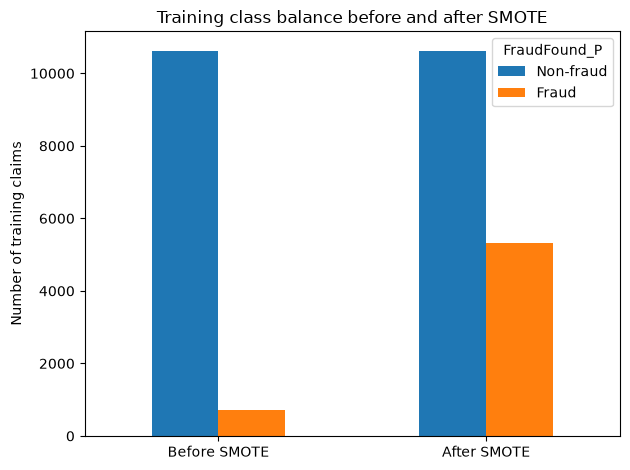

In [15]:
X_train_smote, y_train_smote = smote_resample(X_train, y_train, scaler, best_ratio, best_k)

# Each synthetic claim must have exactly one category per original column
assert (X_train_smote[one_hot_columns].sum(axis=1) == len(category_columns)).all()
assert list(X_train_smote.columns) == list(X_test_ready.columns)

class_counts = pd.DataFrame({
    'Before SMOTE': y_train.value_counts().sort_index(),
    'After SMOTE': y_train_smote.value_counts().sort_index()
}).rename(index={0: 'Non-fraud', 1: 'Fraud'})
display(class_counts)
print('Synthetic fraud claims added:', len(y_train_smote) - len(y_train))
print('Hold-out set is unchanged:', X_test_ready.shape)

class_counts.T.plot(kind='bar', rot=0)
plt.ylabel('Number of training claims')
plt.title('Training class balance before and after SMOTE')
plt.tight_layout()
plt.show()

# Train Logistic Regression on the SMOTE training data

In [16]:
# No class_weight here: SMOTE already rebalances the classes, so weighting as well would correct twice
smote_model = LogisticRegression(max_iter=1000, random_state=42)
smote_model.fit(X_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

# Evaluate once on the same hold-out
Same metrics and the same 0.5 threshold as the baseline.

**Note on the threshold:** a 0.5 cutoff only means "equally likely" when the model was trained on balanced classes. If the chosen `sampling_strategy` is below 1.0, the SMOTE model will flag fewer claims at 0.5, which lowers recall without the model actually being worse at ranking claims. PR-AUC and the top-10–20% table below do not depend on the threshold, so they are the fairer comparison.

In [17]:
smote_probabilities = smote_model.predict_proba(X_test_ready)[:, 1]
smote_predictions = (smote_probabilities >= 0.5).astype(int)

smote_row = pd.DataFrame({
    'Approach': ['Logistic regression + SMOTE'],
    'Accuracy': [accuracy_score(y_test, smote_predictions)],
    'Precision': [precision_score(y_test, smote_predictions, zero_division=0)],
    'Recall': [recall_score(y_test, smote_predictions, zero_division=0)],
    'F1': [f1_score(y_test, smote_predictions, zero_division=0)],
    'PR-AUC / AP': [average_precision_score(y_test, smote_probabilities)]
})
comparison = pd.concat([results, smote_row], ignore_index=True)
comparison['Approach'] = comparison['Approach'].replace(
    {'Logistic regression': 'Logistic regression (class_weight=balanced)'})
comparison['% of claims flagged'] = [0.0, test_predictions.mean() * 100, smote_predictions.mean() * 100]
display(comparison.round(4))

,Approach,Accuracy,Precision,Recall,F1,PR-AUC / AP,% of claims flagged
0,Always non-fraud reference,0.9478,0.0000,0.0000,0.0000,0.0522,0.0000
1,Logistic regression (class_weight=balanced),0.6111,0.0662,0.4930,0.1168,0.0653,38.8195
2,Logistic regression + SMOTE,0.8068,0.0542,0.1643,0.0815,0.0649,15.8217


# Business metric: % of fraud caught if investigators review only the top-scored claims
From the project success criteria: rank all 1996 claims by predicted fraud probability and count how much fraud lands in the top 10%, 15% and 20%.

In [18]:
# Business view: if investigators only review the highest-scored claims, what share of fraud do they catch?
# This does not depend on the 0.5 threshold, so it compares the two models fairly.
review_shares = [0.10, 0.15, 0.20]
total_fraud = y_test.sum()
review_rows = []
for share in review_shares:
    claims_reviewed = int(np.ceil(share * len(y_test)))
    row = {'Top % of claims reviewed': f'{share:.0%}', 'Claims reviewed': claims_reviewed}
    for label, probabilities in [('Baseline', test_probabilities), ('SMOTE', smote_probabilities)]:
        top_claims = np.argsort(-probabilities)[:claims_reviewed]
        fraud_caught = y_test.to_numpy()[top_claims].sum()
        row[f'{label}: fraud caught'] = fraud_caught
        row[f'{label}: % of fraud caught'] = round(fraud_caught / total_fraud * 100, 2)
    review_rows.append(row)
display(pd.DataFrame(review_rows))
print('Total fraud cases in hold-out:', total_fraud)

,Top % of claims reviewed,Claims reviewed,Baseline: fraud caught,Baseline: % of fraud caught,SMOTE: fraud caught,SMOTE: % of fraud caught
0,10%,409,19,8.92,16,7.51
1,15%,613,32,15.02,33,15.49
2,20%,817,48,22.54,42,19.72


Total fraud cases in hold-out: 213


# Confusion matrices: baseline vs. SMOTE

,Predicted non-fraud,Predicted fraud
Actual non fraud,3259,611
Actual fraud,178,35


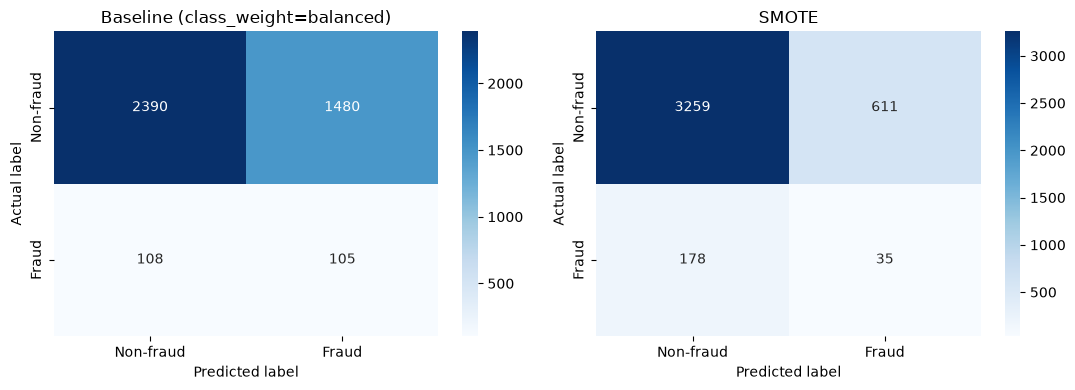

Correctly identified non-fraud: 3259
False alarms: 611
Missed fraud: 178
Fraud cases caught: 35


In [19]:
smote_matrix = confusion_matrix(y_test, smote_predictions, labels=[0, 1])
display(pd.DataFrame(smote_matrix, index=['Actual non fraud', 'Actual fraud'],
                     columns=['Predicted non-fraud', 'Predicted fraud']))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, cm, title in zip(axes, [matrix, smote_matrix],
                           ['Baseline (class_weight=balanced)', 'SMOTE']):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axis,
                xticklabels=['Non-fraud', 'Fraud'], yticklabels=['Non-fraud', 'Fraud'])
    axis.set_xlabel('Predicted label')
    axis.set_ylabel('Actual label')
    axis.set_title(title)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = smote_matrix.ravel()
print('Correctly identified non-fraud:', tn)
print('False alarms:', fp)
print('Missed fraud:', fn)
print('Fraud cases caught:', tp)

# Precision-recall curves

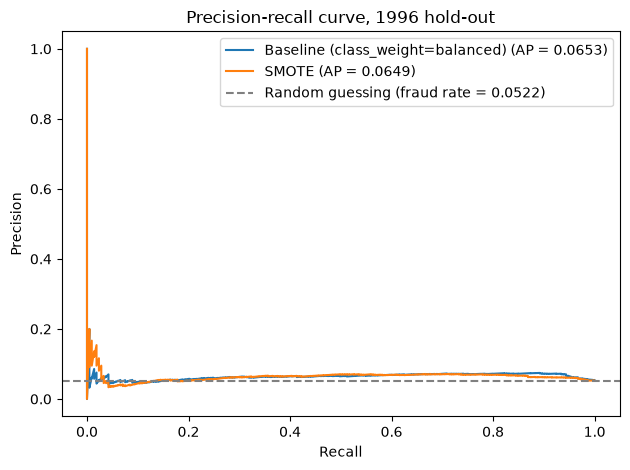

In [20]:
# Precision-recall curves compare the two models at every threshold, not only at 0.5
for probabilities, label in [(test_probabilities, 'Baseline (class_weight=balanced)'),
                             (smote_probabilities, 'SMOTE')]:
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    plt.plot(recall, precision,
             label=f'{label} (AP = {average_precision_score(y_test, probabilities):.4f})')
plt.axhline(y_test.mean(), color='grey', linestyle='--',
            label=f'Random guessing (fraud rate = {y_test.mean():.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-recall curve, 1996 hold-out')
plt.legend()
plt.tight_layout()
plt.show()

# Summary
*(Numbers are from the run saved in this notebook; all random steps use `random_state=42`.)*

- **SMOTE did not improve on the baseline.** Hold-out PR-AUC is about the same (0.0649 with SMOTE vs. 0.0653 with `class_weight='balanced'`), and the top-10–20% review metric is roughly a tie (each model wins at a different cutoff).
- At the 0.5 threshold, the SMOTE model flags fewer claims (about 16% vs. 39%), so it has fewer false alarms but also lower recall. This is mostly a threshold effect, not a better or worse model.
- On validation, all SMOTE settings scored within about 0.002 PR-AUC of each other, so the amount of oversampling barely matters here.
- Both models are only slightly better than random guessing (PR-AUC of random = fraud rate = 0.052). For logistic regression, *how* we handle imbalance (SMOTE vs. class weights) is not the bottleneck. The bigger gains are likely to come from feature engineering and non-linear models (random forest, gradient boosting), where SMOTE vs. class weighting can be compared again.